<a href="https://colab.research.google.com/github/hannnnnnnny/INFOSYS722_Iteration4_BDAS/blob/main/INFOSYS722_Iteration4_BDAS_yhan606.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
%pip -q install pyspark

In [3]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("INFOSYS722_Iteration4_BDAS")
    .master("local[*]")
    .getOrCreate()
)

print("Spark version:", spark.version)

Spark version: 4.0.4


In [ ]:

from pyspark.sql import functions as F

mbie = spark.read.csv(
    "/content/data/MBIE_Jobs_Online_Quarterly_Dec2025_RAW.csv",
    header=True,
    inferSchema=True
)

unemployment = spark.read.csv(
    "/content/data/StatsNZ_Unemployment_Quarterly.csv",
    header=True,
    inferSchema=True
)

print("MBIE rows:", mbie.count())
print("Stats NZ rows:", unemployment.count())

print("\nMBIE schema:")
mbie.printSchema()

print("\nStats NZ schema:")
unemployment.printSchema()

mbie.show(5, truncate=False)
unemployment.show(5, truncate=False)


MBIE rows: 17446
Stats NZ rows: 61

MBIE schema:
root
 |-- ACTUAL_DATE: string (nullable = true)
 |-- KEYA: string (nullable = true)
 |-- KEYBB: string (nullable = true)
 |-- AVI_SUM: double (nullable = true)


Stats NZ schema:
root
 |-- ACTUAL_DATE: string (nullable = true)
 |-- Unemployment_Rate: double (nullable = true)

+-----------+--------+--------------------------------------+-------+
|ACTUAL_DATE|KEYA    |KEYBB                                 |AVI_SUM|
+-----------+--------+--------------------------------------+-------+
|01/12/2010 |Auckland|Business services                     |100.0  |
|01/12/2010 |Auckland|Clerical and Administrative Workers   |100.0  |
|01/12/2010 |Auckland|Community and Personal Service Workers|100.0  |
|01/12/2010 |Auckland|Construction                          |100.0  |
|01/12/2010 |Auckland|Education                             |100.0  |
+-----------+--------+--------------------------------------+-------+
only showing top 5 rows
+-----------+-------

In [5]:

from pyspark.sql import functions as F

# Convert date strings to Spark date type
mbie = mbie.withColumn(
    "ACTUAL_DATE",
    F.to_date("ACTUAL_DATE", "dd/MM/yyyy")
)

unemployment = unemployment.withColumn(
    "ACTUAL_DATE",
    F.to_date("ACTUAL_DATE", "dd/MM/yyyy")
)

# Dataset description
print("STEP 2.2 - DESCRIBE THE DATA")

mbie.printSchema()

print("Rows:", mbie.count())
print("Regions (KEYA):", mbie.select("KEYA").distinct().count())
print("Categories (KEYBB):", mbie.select("KEYBB").distinct().count())

print("\nAVI descriptive statistics:")
mbie.select("AVI_SUM").summary().show()

print("\nDate range:")
mbie.select(
    F.min("ACTUAL_DATE").alias("Start_Date"),
    F.max("ACTUAL_DATE").alias("End_Date")
).show()

print("\nSeries observation counts:")
(
    mbie.groupBy("KEYA", "KEYBB")
    .count()
    .groupBy("count")
    .count()
    .orderBy("count")
    .show()
)

print("\nStats NZ schema:")
unemployment.printSchema()


STEP 2.2 - DESCRIBE THE DATA
root
 |-- ACTUAL_DATE: date (nullable = true)
 |-- KEYA: string (nullable = true)
 |-- KEYBB: string (nullable = true)
 |-- AVI_SUM: double (nullable = true)

Rows: 17446
Regions (KEYA): 11
Categories (KEYBB): 36

AVI descriptive statistics:
+-------+------------------+
|summary|           AVI_SUM|
+-------+------------------+
|  count|             17446|
|   mean|244.32386277656707|
| stddev|149.34109656544618|
|    min|             11.11|
|    25%|            139.57|
|    50%|             200.8|
|    75%|            306.38|
|    max|           1441.18|
+-------+------------------+


Date range:
+----------+----------+
|Start_Date|  End_Date|
+----------+----------+
|2010-12-01|2025-12-01|
+----------+----------+


Series observation counts:
+-----+-----+
|count|count|
+-----+-----+
|   61|  286|
+-----+-----+


Stats NZ schema:
root
 |-- ACTUAL_DATE: date (nullable = true)
 |-- Unemployment_Rate: double (nullable = true)



STEP 2.3 - EXPLORE THE DATA
+-----------------+------------------+------+
|         Skewness|           Std_Dev|Median|
+-----------------+------------------+------+
|1.794565673252251|149.34109656544618| 200.8|
+-----------------+------------------+------+



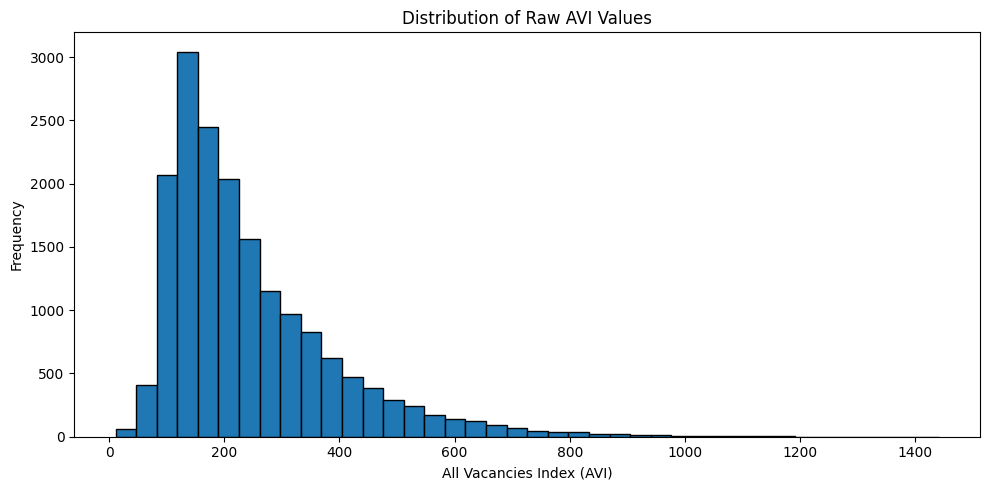

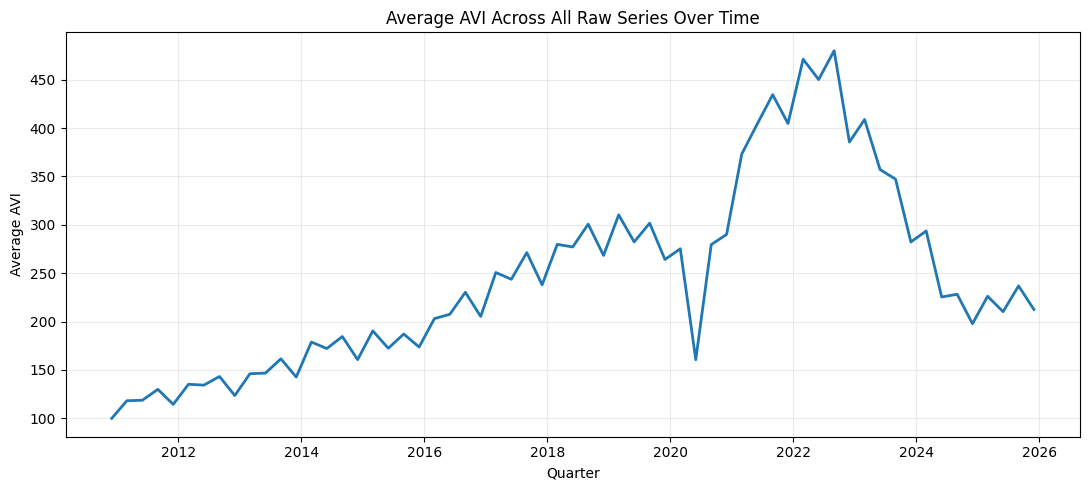

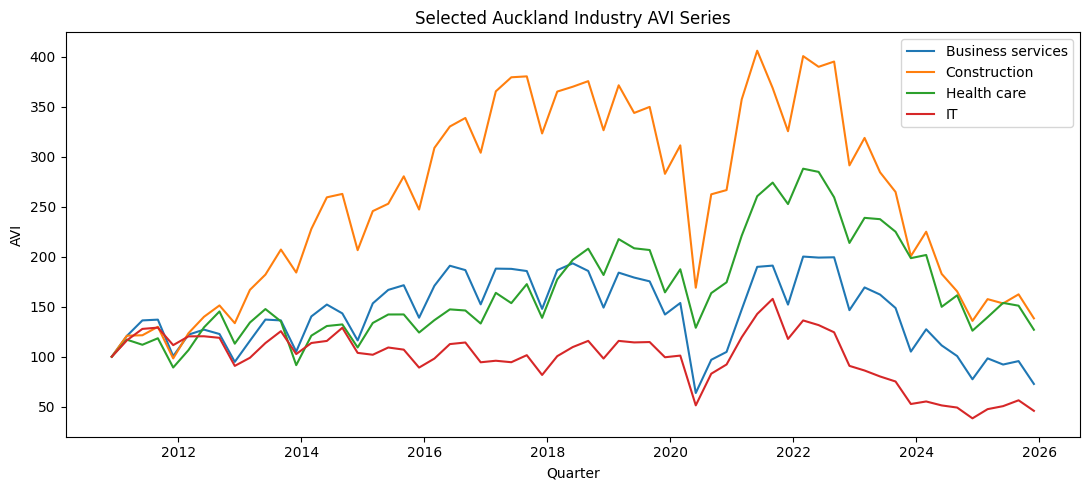

In [6]:

import matplotlib.pyplot as plt
from pyspark.sql import functions as F

print("STEP 2.3 - EXPLORE THE DATA")

# 1. Calculate distribution statistics in Spark
mbie.select(
    F.skewness("AVI_SUM").alias("Skewness"),
    F.stddev("AVI_SUM").alias("Std_Dev"),
    F.expr("percentile_approx(AVI_SUM, 0.5)").alias("Median")
).show()

# 2. AVI distribution
# Collect the single numeric column for plotting only
avi_values = [
    row["AVI_SUM"]
    for row in mbie.select("AVI_SUM").collect()
]

plt.figure(figsize=(10, 5))
plt.hist(avi_values, bins=40, edgecolor="black")
plt.xlabel("All Vacancies Index (AVI)")
plt.ylabel("Frequency")
plt.title("Distribution of Raw AVI Values")
plt.tight_layout()
plt.show()

# 3. Quarterly mean AVI calculated using Spark
quarterly = (
    mbie.groupBy("ACTUAL_DATE")
    .agg(F.avg("AVI_SUM").alias("Mean_AVI"))
    .orderBy("ACTUAL_DATE")
    .collect()
)

dates = [row["ACTUAL_DATE"] for row in quarterly]
means = [row["Mean_AVI"] for row in quarterly]

plt.figure(figsize=(11, 5))
plt.plot(dates, means, linewidth=2)
plt.xlabel("Quarter")
plt.ylabel("Average AVI")
plt.title("Average AVI Across All Raw Series Over Time")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# 4. Compare selected Auckland industry series
selected_categories = [
    "Business services",
    "Construction",
    "Health care",
    "IT"
]

akl_rows = (
    mbie.filter(
        (F.col("KEYA") == "Auckland") &
        (F.col("KEYBB").isin(selected_categories))
    )
    .select("ACTUAL_DATE", "KEYBB", "AVI_SUM")
    .orderBy("ACTUAL_DATE")
    .collect()
)

plt.figure(figsize=(11, 5))

for category in selected_categories:
    records = [
        row for row in akl_rows
        if row["KEYBB"] == category
    ]
    plt.plot(
        [r["ACTUAL_DATE"] for r in records],
        [r["AVI_SUM"] for r in records],
        label=category
    )

plt.xlabel("Quarter")
plt.ylabel("AVI")
plt.title("Selected Auckland Industry AVI Series")
plt.legend()
plt.tight_layout()
plt.show()


In [7]:

from pyspark.sql import functions as F

print("STEP 2.4 - VERIFY DATA QUALITY")

# 1. Missing and null values
print("\n1. Missing values by column")
missing = mbie.select([
    F.sum(
        F.when(
            F.col(c).isNull() |
            (F.trim(F.col(c).cast("string")) == ""),
            1
        ).otherwise(0)
    ).alias(c)
    for c in mbie.columns
])
missing.show()

# 2. Duplicate full rows
print("\n2. Exact duplicate rows")
print("Duplicates:", mbie.count() - mbie.distinct().count())

# 3. Duplicate series-quarter keys
print("\n3. Duplicate date-region-category keys")
duplicate_keys = (
    mbie.groupBy("ACTUAL_DATE", "KEYA", "KEYBB")
    .count()
    .filter(F.col("count") > 1)
)
print("Duplicate keys:", duplicate_keys.count())

# 4. AVI validity
print("\n4. AVI validity")
mbie.select(
    F.min("AVI_SUM").alias("Min_AVI"),
    F.max("AVI_SUM").alias("Max_AVI"),
    F.sum(
        F.when(F.col("AVI_SUM") <= 0, 1).otherwise(0)
    ).alias("Non_Positive_AVI"),
    F.sum(
        F.when(F.isnan("AVI_SUM"), 1).otherwise(0)
    ).alias("NaN_AVI")
).show()

# 5. Quarterly completeness
print("\n5. Quarterly series completeness")
series_counts = (
    mbie.groupBy("KEYA", "KEYBB")
    .count()
)

series_counts.groupBy("count").count().show()

# 6. Stats NZ checks
print("\n6. Stats NZ missing values")
unemployment.select(
    F.sum(
        F.when(F.col("ACTUAL_DATE").isNull(), 1).otherwise(0)
    ).alias("Missing_Date"),
    F.sum(
        F.when(
            F.col("Unemployment_Rate").isNull() |
            F.isnan("Unemployment_Rate"),
            1
        ).otherwise(0)
    ).alias("Missing_Rate")
).show()

print("\nStats NZ duplicate quarters:")
print(
    unemployment.count()
    - unemployment.select("ACTUAL_DATE").distinct().count()
)

print("\nSTEP 2.4 COMPLETE")


STEP 2.4 - VERIFY DATA QUALITY

1. Missing values by column
+-----------+----+-----+-------+
|ACTUAL_DATE|KEYA|KEYBB|AVI_SUM|
+-----------+----+-----+-------+
|          0|   0|    0|      0|
+-----------+----+-----+-------+


2. Exact duplicate rows
Duplicates: 0

3. Duplicate date-region-category keys
Duplicate keys: 0

4. AVI validity
+-------+-------+----------------+-------+
|Min_AVI|Max_AVI|Non_Positive_AVI|NaN_AVI|
+-------+-------+----------------+-------+
|  11.11|1441.18|               0|      0|
+-------+-------+----------------+-------+


5. Quarterly series completeness
+-----+-----+
|count|count|
+-----+-----+
|   61|  286|
+-----+-----+


6. Stats NZ missing values
+------------+------------+
|Missing_Date|Missing_Rate|
+------------+------------+
|           0|           0|
+------------+------------+


Stats NZ duplicate quarters:
0

STEP 2.4 COMPLETE


In [8]:

from pyspark.sql import functions as F

print("STEP 3.1 - SELECT THE DATA")

# Exact category names from the original MBIE data
industries = [
    "Business services",
    "Construction",
    "Education",
    "Health care",
    "Hospitality",
    "IT",
    "Manufacturing",
    "Primary",
    "Sales"
]

occupations = [
    "Clerical and Administrative Workers",
    "Community and Personal Service Workers",
    "Labourers",
    "Machinery Operators and Drivers",
    "Managers",
    "Professionals",
    "Sales Workers",
    "Technicians and Trades Workers"
]

selected_categories = industries + occupations

# Select regional observations, excluding national total
selected = (
    mbie.filter(
        (F.col("KEYA") != "Totals") &
        F.col("KEYBB").isin(selected_categories)
    )
    .select("ACTUAL_DATE", "KEYA", "KEYBB", "AVI_SUM")
)

print("Selected rows:", selected.count())
print("Selected regions:",
      selected.select("KEYA").distinct().count())
print("Selected categories:",
      selected.select("KEYBB").distinct().count())
print("Selected series:",
      selected.select("KEYA", "KEYBB").distinct().count())

selected.groupBy("KEYA").count().orderBy("KEYA").show(
    truncate=False
)

assert selected.count() == 10370
assert selected.select("KEYA", "KEYBB").distinct().count() == 170

print("STEP 3.1 COMPLETE")


STEP 3.1 - SELECT THE DATA
Selected rows: 10370
Selected regions: 10
Selected categories: 17
Selected series: 170
+------------------------------------+-----+
|KEYA                                |count|
+------------------------------------+-----+
|Auckland                            |1037 |
|Bay of Plenty                       |1037 |
|Canterbury                          |1037 |
|Gisborne/Hawkes Bay                 |1037 |
|Manawatu-Whanganui/Taranaki         |1037 |
|Northland                           |1037 |
|Otago/Southland                     |1037 |
|Tasman/Nelson/Marlborough/West Coast|1037 |
|Waikato                             |1037 |
|Wellington                          |1037 |
+------------------------------------+-----+

STEP 3.1 COMPLETE


In [9]:

from pyspark.sql import functions as F
from pyspark.sql.window import Window

print("STEP 3.2 - CLEAN THE DATA")

# Verify the selected source records
missing = selected.select([
    F.sum(
        F.when(F.col(c).isNull(), 1).otherwise(0)
    ).alias(c)
    for c in selected.columns
])

print("\nMissing values:")
missing.show()

duplicate_keys = (
    selected.groupBy("ACTUAL_DATE", "KEYA", "KEYBB")
    .count()
    .filter(F.col("count") > 1)
    .count()
)

print("Duplicate series-quarter keys:", duplicate_keys)

# Preserve chronological order within each series.
# Sorting is important before constructing lag features.
cleaned = selected.orderBy(
    "KEYA", "KEYBB", "ACTUAL_DATE"
)

print("Cleaned rows:", cleaned.count())
cleaned.show(5, truncate=False)

assert cleaned.count() == 10370
assert duplicate_keys == 0

print("STEP 3.2 COMPLETE")


STEP 3.2 - CLEAN THE DATA

Missing values:
+-----------+----+-----+-------+
|ACTUAL_DATE|KEYA|KEYBB|AVI_SUM|
+-----------+----+-----+-------+
|          0|   0|    0|      0|
+-----------+----+-----+-------+

Duplicate series-quarter keys: 0
Cleaned rows: 10370
+-----------+--------+-----------------+-------+
|ACTUAL_DATE|KEYA    |KEYBB            |AVI_SUM|
+-----------+--------+-----------------+-------+
|2010-12-01 |Auckland|Business services|100.0  |
|2011-03-01 |Auckland|Business services|120.84 |
|2011-06-01 |Auckland|Business services|136.33 |
|2011-09-01 |Auckland|Business services|137.09 |
|2011-12-01 |Auckland|Business services|100.53 |
+-----------+--------+-----------------+-------+
only showing top 5 rows
STEP 3.2 COMPLETE


In [10]:

from pyspark.sql import functions as F
from pyspark.sql.window import Window

print("STEP 3.3 - CONSTRUCT NEW FIELDS")

# Define one chronological window per region-category series
series_window = (
    Window.partitionBy("KEYA", "KEYBB")
    .orderBy("ACTUAL_DATE")
)

# Create five historical AVI predictors
lagged = cleaned

for lag_num in range(1, 6):
    lagged = lagged.withColumn(
        f"AVI_SUM__{lag_num}",
        F.lag("AVI_SUM", lag_num).over(series_window)
    )

# Series identifier for later modelling
lagged = lagged.withColumn(
    "Series_ID",
    F.concat_ws(" | ", F.col("KEYA"), F.col("KEYBB"))
)

print("Rows before lag removal:", lagged.count())

lag_columns = [f"AVI_SUM__{i}" for i in range(1, 6)]

# Remove only records without a complete five-quarter history
prepared_lags = lagged.dropna(subset=lag_columns)

print("Rows after lag removal:", prepared_lags.count())
print(
    "Number of series:",
    prepared_lags.select("Series_ID").distinct().count()
)

print("\nDate range:")
prepared_lags.select(
    F.min("ACTUAL_DATE").alias("Start"),
    F.max("ACTUAL_DATE").alias("End")
).show()

print("\nExample of historical lag predictors:")
(
    prepared_lags
    .filter(
        (F.col("KEYA") == "Auckland") &
        (F.col("KEYBB") == "Business services")
    )
    .select("ACTUAL_DATE", "AVI_SUM", *lag_columns)
    .orderBy("ACTUAL_DATE")
    .show(6, truncate=False)
)

assert prepared_lags.count() == 9520
assert prepared_lags.select("Series_ID").distinct().count() == 170

print("STEP 3.3 COMPLETE")


STEP 3.3 - CONSTRUCT NEW FIELDS
Rows before lag removal: 10370
Rows after lag removal: 9520
Number of series: 170

Date range:
+----------+----------+
|     Start|       End|
+----------+----------+
|2012-03-01|2025-12-01|
+----------+----------+


Example of historical lag predictors:
+-----------+-------+----------+----------+----------+----------+----------+
|ACTUAL_DATE|AVI_SUM|AVI_SUM__1|AVI_SUM__2|AVI_SUM__3|AVI_SUM__4|AVI_SUM__5|
+-----------+-------+----------+----------+----------+----------+----------+
|2012-03-01 |122.08 |100.53    |137.09    |136.33    |120.84    |100.0     |
|2012-06-01 |127.09 |122.08    |100.53    |137.09    |136.33    |120.84    |
|2012-09-01 |122.72 |127.09    |122.08    |100.53    |137.09    |136.33    |
|2012-12-01 |94.84  |122.72    |127.09    |122.08    |100.53    |137.09    |
|2013-03-01 |115.94 |94.84     |122.72    |127.09    |122.08    |100.53    |
|2013-06-01 |137.15 |115.94    |94.84     |122.72    |127.09    |122.08    |
+-----------+-------

In [11]:

from pyspark.sql import functions as F

print("STEP 3.4 - INTEGRATE THE DATA")

# Create category lookup table using the category lists
# already defined in Step 3.1
category_rows = (
    [(name, "Industry") for name in industries]
    + [(name, "Occupation") for name in occupations]
)

category_lookup = spark.createDataFrame(
    category_rows,
    ["KEYBB", "Category_Type"]
)

# Join employment category classification
classified = prepared_lags.join(
    F.broadcast(category_lookup),
    on="KEYBB",
    how="left"
)

print("Rows after category integration:", classified.count())

classified.groupBy("Category_Type").count().show()

# Integrate quarterly Stats NZ unemployment data
integrated = classified.join(
    F.broadcast(unemployment),
    on="ACTUAL_DATE",
    how="left"
)

print("Rows after Stats NZ integration:", integrated.count())

print("Missing category types:",
      integrated.filter(F.col("Category_Type").isNull()).count())

print("Missing unemployment rates:",
      integrated.filter(F.col("Unemployment_Rate").isNull()).count())

print("\nIntegrated data sample:")
(
    integrated
    .select(
        "ACTUAL_DATE",
        "KEYA",
        "KEYBB",
        "Category_Type",
        "AVI_SUM",
        "Unemployment_Rate"
    )
    .orderBy("KEYA", "KEYBB", "ACTUAL_DATE")
    .show(8, truncate=False)
)

assert integrated.count() == 9520
assert integrated.filter(F.col("Category_Type").isNull()).count() == 0
assert integrated.filter(F.col("Unemployment_Rate").isNull()).count() == 0

print("STEP 3.4 COMPLETE")


STEP 3.4 - INTEGRATE THE DATA
Rows after category integration: 9520
+-------------+-----+
|Category_Type|count|
+-------------+-----+
|   Occupation| 4480|
|     Industry| 5040|
+-------------+-----+

Rows after Stats NZ integration: 9520
Missing category types: 0
Missing unemployment rates: 0

Integrated data sample:
+-----------+--------+-----------------+-------------+-------+-----------------+
|ACTUAL_DATE|KEYA    |KEYBB            |Category_Type|AVI_SUM|Unemployment_Rate|
+-----------+--------+-----------------+-------------+-------+-----------------+
|2012-03-01 |Auckland|Business services|Industry     |122.08 |6.4              |
|2012-06-01 |Auckland|Business services|Industry     |127.09 |6.4              |
|2012-09-01 |Auckland|Business services|Industry     |122.72 |6.7              |
|2012-12-01 |Auckland|Business services|Industry     |94.84  |6.3              |
|2013-03-01 |Auckland|Business services|Industry     |115.94 |5.8              |
|2013-06-01 |Auckland|Business s

In [12]:

from pyspark.sql import functions as F
from pyspark.sql.types import DoubleType, StringType

print("STEP 3.5 - FORMAT THE DATA")

# Create calendar fields
formatted = (
    integrated
    .withColumn("Year", F.year("ACTUAL_DATE"))
    .withColumn("Quarter", F.quarter("ACTUAL_DATE"))
)

# Ensure numerical fields use DoubleType
numeric_columns = (
    ["AVI_SUM", "Unemployment_Rate"]
    + [f"AVI_SUM__{i}" for i in range(1, 6)]
)

for column in numeric_columns:
    formatted = formatted.withColumn(
        column,
        F.col(column).cast(DoubleType())
    )

# Ensure identifiers use StringType for Spark ML encoding
for column in ["KEYA", "KEYBB", "Category_Type", "Series_ID"]:
    formatted = formatted.withColumn(
        column,
        F.col(column).cast(StringType())
    )

print("\nFinal schema:")
formatted.printSchema()

print("\nRows before integration: 9520")
print("Rows after formatting:", formatted.count())

print("\nYear and quarter example:")
(
    formatted
    .select(
        "ACTUAL_DATE",
        "Year",
        "Quarter",
        "KEYA",
        "KEYBB",
        "AVI_SUM",
        "Unemployment_Rate"
    )
    .orderBy("ACTUAL_DATE", "KEYA", "KEYBB")
    .show(8, truncate=False)
)

assert formatted.count() == 9520

print("STEP 3.5 COMPLETE")


STEP 3.5 - FORMAT THE DATA

Final schema:
root
 |-- ACTUAL_DATE: date (nullable = true)
 |-- KEYBB: string (nullable = true)
 |-- KEYA: string (nullable = true)
 |-- AVI_SUM: double (nullable = true)
 |-- AVI_SUM__1: double (nullable = true)
 |-- AVI_SUM__2: double (nullable = true)
 |-- AVI_SUM__3: double (nullable = true)
 |-- AVI_SUM__4: double (nullable = true)
 |-- AVI_SUM__5: double (nullable = true)
 |-- Series_ID: string (nullable = false)
 |-- Category_Type: string (nullable = true)
 |-- Unemployment_Rate: double (nullable = true)
 |-- Year: integer (nullable = true)
 |-- Quarter: integer (nullable = true)


Rows before integration: 9520
Rows after formatting: 9520

Year and quarter example:
+-----------+----+-------+--------+--------------------------------------+-------+-----------------+
|ACTUAL_DATE|Year|Quarter|KEYA    |KEYBB                                 |AVI_SUM|Unemployment_Rate|
+-----------+----+-------+--------+--------------------------------------+-------+------

In [13]:

from pyspark.sql import functions as F

print("STEP 4.1 - REDUCE THE DATA")

lag_columns = [f"AVI_SUM__{i}" for i in range(1, 6)]

# Keep columns needed for modelling and diagnostics
model_data = formatted.select(
    "ACTUAL_DATE",
    "Year",
    "Quarter",
    "KEYA",
    "KEYBB",
    "Category_Type",
    "Series_ID",
    "AVI_SUM",
    *lag_columns,
    "Unemployment_Rate"
)

# Use chronological development and evaluation periods
development = model_data.filter(
    F.col("ACTUAL_DATE") <= F.lit("2022-12-01").cast("date")
)

historical_evaluation = model_data.filter(
    F.col("ACTUAL_DATE") >= F.lit("2023-03-01").cast("date")
)

print("All modelling rows:", model_data.count())
print("Development rows:", development.count())
print("Historical evaluation rows:", historical_evaluation.count())

print("\nCandidate predictors:", lag_columns)

assert model_data.count() == 9520
assert development.count() == 7480
assert historical_evaluation.count() == 2040

print("STEP 4.1 - INITIAL DATA REDUCTION COMPLETE")


STEP 4.1 - REDUCE THE DATA
All modelling rows: 9520
Development rows: 7480
Historical evaluation rows: 2040

Candidate predictors: ['AVI_SUM__1', 'AVI_SUM__2', 'AVI_SUM__3', 'AVI_SUM__4', 'AVI_SUM__5']
STEP 4.1 - INITIAL DATA REDUCTION COMPLETE


STEP 4.2 - PROJECT THE DATA

Original vs log-transformed AVI:
+------------------+-------------------+----------------+------------------+
|Original_Skewness |Log_Skewness       |Original_SD     |Log_SD            |
+------------------+-------------------+----------------+------------------+
|1.7887887781034455|0.14201299906108517|155.360603187866|0.5572073975763261|
+------------------+-------------------+----------------+------------------+



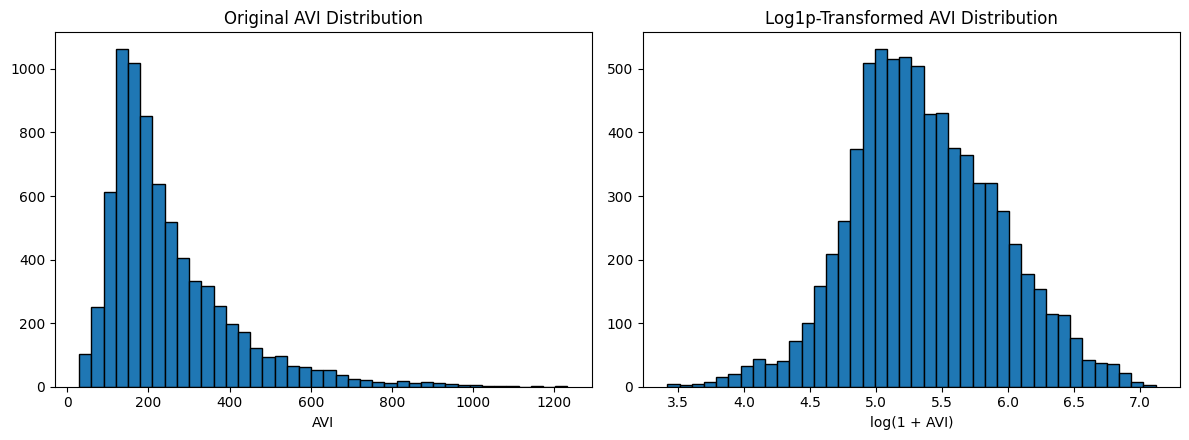

Development rows: 7480
STEP 4.2 COMPLETE


In [14]:

from pyspark.sql import functions as F
import matplotlib.pyplot as plt

print("STEP 4.2 - PROJECT THE DATA")

# Work with development data only
transformed_dev = development.withColumn(
    "Log_AVI",
    F.log1p(F.col("AVI_SUM"))
)

# Create log-transformed historical predictors
for i in range(1, 6):
    transformed_dev = transformed_dev.withColumn(
        f"Log_AVI_Lag_{i}",
        F.log1p(F.col(f"AVI_SUM__{i}"))
    )

# Compare distribution statistics
print("\nOriginal vs log-transformed AVI:")

transformed_dev.select(
    F.skewness("AVI_SUM").alias("Original_Skewness"),
    F.skewness("Log_AVI").alias("Log_Skewness"),
    F.stddev("AVI_SUM").alias("Original_SD"),
    F.stddev("Log_AVI").alias("Log_SD")
).show(truncate=False)

# Only collect values for visualisation
plot_df = transformed_dev.select(
    "AVI_SUM", "Log_AVI"
).toPandas()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].hist(
    plot_df["AVI_SUM"],
    bins=40,
    edgecolor="black"
)
axes[0].set_title("Original AVI Distribution")
axes[0].set_xlabel("AVI")

axes[1].hist(
    plot_df["Log_AVI"],
    bins=40,
    edgecolor="black"
)
axes[1].set_title("Log1p-Transformed AVI Distribution")
axes[1].set_xlabel("log(1 + AVI)")

plt.tight_layout()
plt.show()

print("Development rows:", transformed_dev.count())
print("STEP 4.2 COMPLETE")


In [15]:

import numpy as np
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.regression import LinearRegression
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.sql import functions as F

print("STEP 4.2 - TRANSFORMATION VALIDATION")

lag_columns = [f"AVI_SUM__{i}" for i in range(1, 6)]
log_lags = [f"Log_AVI_Lag_{i}" for i in range(1, 6)]

folds = [
    (2018, 2019),
    (2019, 2020),
    (2020, 2021),
    (2021, 2022)
]

def make_pipeline(features, standardise=False):
    assembler = VectorAssembler(
        inputCols=features,
        outputCol="raw_features"
    )

    stages = [assembler]
    feature_col = "raw_features"

    if standardise:
        stages.append(StandardScaler(
            inputCol="raw_features",
            outputCol="scaled_features",
            withStd=True,
            withMean=True
        ))
        feature_col = "scaled_features"

    stages.append(LinearRegression(
        featuresCol=feature_col,
        labelCol="label",
        predictionCol="prediction",
        regParam=0.0,
        maxIter=100
    ))

    return Pipeline(stages=stages)


experiment_configs = [
    ("Original", lag_columns, False, False),
    ("Standardised", lag_columns, True, False),
    ("Log1p", log_lags, False, True)
]

validation_results = []

for experiment, features, standardise, is_log in experiment_configs:
    for train_end, validation_year in folds:

        train = transformed_dev.filter(
            F.col("Year") <= train_end
        )

        valid = transformed_dev.filter(
            F.col("Year") == validation_year
        )

        label = "Log_AVI" if is_log else "AVI_SUM"

        train = train.withColumn("label", F.col(label))
        valid = valid.withColumn("label", F.col(label))

        pipeline = make_pipeline(features, standardise)
        fitted = pipeline.fit(train)
        predicted = fitted.transform(valid)

        if is_log:
            predicted = predicted.withColumn(
                "Predicted_AVI",
                F.expm1(F.col("prediction"))
            )
        else:
            predicted = predicted.withColumn(
                "Predicted_AVI",
                F.col("prediction")
            )

        evaluator = RegressionEvaluator(
            labelCol="AVI_SUM",
            predictionCol="Predicted_AVI",
            metricName="mae"
        )

        mae = evaluator.evaluate(predicted)

        validation_results.append(
            (experiment, validation_year, float(mae))
        )

        print(
            experiment,
            validation_year,
            "MAE:",
            round(mae, 3)
        )


results_df = spark.createDataFrame(
    validation_results,
    ["Transformation", "Validation_Year", "MAE"]
)

print("\nMean MAE by transformation:")
(
    results_df.groupBy("Transformation")
    .agg(
        F.avg("MAE").alias("Mean_MAE"),
        F.stddev("MAE").alias("SD_MAE")
    )
    .orderBy("Mean_MAE")
    .show(truncate=False)
)

print("STEP 4.2 TRANSFORMATION VALIDATION COMPLETE")


STEP 4.2 - TRANSFORMATION VALIDATION
Original 2019 MAE: 25.824
Original 2020 MAE: 61.437
Original 2021 MAE: 76.441
Original 2022 MAE: 50.143
Standardised 2019 MAE: 25.824
Standardised 2020 MAE: 61.437
Standardised 2021 MAE: 76.441
Standardised 2022 MAE: 50.143
Log1p 2019 MAE: 27.427
Log1p 2020 MAE: 61.842
Log1p 2021 MAE: 85.71
Log1p 2022 MAE: 48.19

Mean MAE by transformation:
+--------------+-----------------+------------------+
|Transformation|Mean_MAE         |SD_MAE            |
+--------------+-----------------+------------------+
|Standardised  |53.46116289553645|21.34261573982407 |
|Original      |53.46116289553804|21.342615739826304|
|Log1p         |55.79214169166492|24.45437379369105 |
+--------------+-----------------+------------------+

STEP 4.2 TRANSFORMATION VALIDATION COMPLETE


In [16]:

from pyspark.sql import functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression
from pyspark.ml.evaluation import RegressionEvaluator

print("STEP 4.1B - FEATURE REDUCTION")

all_lags = [f"AVI_SUM__{i}" for i in range(1, 6)]

folds = [
    (2018, 2019),
    (2019, 2020),
    (2020, 2021),
    (2021, 2022)
]

# Full five-lag model and five leave-one-feature-out models
feature_sets = {
    "All five lags": all_lags
}

for removed_lag in all_lags:
    feature_sets[f"Drop {removed_lag}"] = [
        col for col in all_lags if col != removed_lag
    ]

evaluator = RegressionEvaluator(
    labelCol="AVI_SUM",
    predictionCol="prediction",
    metricName="mae"
)

feature_results = []

for name, features in feature_sets.items():
    for train_end, validation_year in folds:

        train = development.filter(
            F.col("Year") <= train_end
        )

        valid = development.filter(
            F.col("Year") == validation_year
        )

        pipeline = Pipeline(stages=[
            VectorAssembler(
                inputCols=features,
                outputCol="features"
            ),
            LinearRegression(
                featuresCol="features",
                labelCol="AVI_SUM",
                predictionCol="prediction",
                regParam=0.0,
                maxIter=100
            )
        ])

        model = pipeline.fit(train)
        predictions = model.transform(valid)

        mae = evaluator.evaluate(predictions)

        feature_results.append(
            (name, validation_year, float(mae))
        )

results = spark.createDataFrame(
    feature_results,
    ["Feature_Set", "Validation_Year", "MAE"]
)

summary = (
    results.groupBy("Feature_Set")
    .agg(
        F.avg("MAE").alias("Mean_MAE"),
        F.stddev("MAE").alias("SD_MAE")
    )
    .orderBy("Mean_MAE")
)

print("\nFeature reduction comparison:")
summary.show(truncate=False)

print("\nDifference from full five-lag model:")

baseline = (
    summary.filter(F.col("Feature_Set") == "All five lags")
    .select("Mean_MAE")
    .first()["Mean_MAE"]
)

summary.withColumn(
    "Delta_MAE",
    F.round(F.col("Mean_MAE") - F.lit(baseline), 4)
).show(truncate=False)

print("STEP 4.1B COMPLETE")


STEP 4.1B - FEATURE REDUCTION

Feature reduction comparison:
+---------------+------------------+------------------+
|Feature_Set    |Mean_MAE          |SD_MAE            |
+---------------+------------------+------------------+
|All five lags  |53.46116289553804 |21.342615739826304|
|Drop AVI_SUM__3|53.59726856714698 |21.22445018805174 |
|Drop AVI_SUM__4|54.70436989443749 |18.763928531652702|
|Drop AVI_SUM__2|54.98887686615355 |22.42304453593636 |
|Drop AVI_SUM__5|55.776475206536404|19.62822196824192 |
|Drop AVI_SUM__1|67.18248174531521 |31.713075253555356|
+---------------+------------------+------------------+


Difference from full five-lag model:
+---------------+------------------+------------------+---------+
|Feature_Set    |Mean_MAE          |SD_MAE            |Delta_MAE|
+---------------+------------------+------------------+---------+
|All five lags  |53.46116289553804 |21.342615739826304|0.0      |
|Drop AVI_SUM__3|53.59726856714698 |21.22445018805174 |0.1361   |
|Drop AVI_

**Step 5.1 — Discuss Data-Mining Methods**

Supervised learning uses known target values to learn a relationship between predictors and outcomes. Regression predicts a continuous numeric value, while classification predicts discrete categories. Unsupervised methods, such as clustering, identify patterns or groups without a predefined target.

**Step 5.2 — Select the Method**

Regression is selected because the objective is to estimate next-quarter AVI as a continuous index. Keeping the original numerical scale supports regional labour-market monitoring and allows errors to be reported in AVI points. Classification would require converting the index into categories, losing information about the magnitude of changes. Clustering could support segmentation, but would not directly produce the required quarterly forecast.

In [17]:


from pyspark.sql import functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import (
    LinearRegression,
    RandomForestRegressor,
    GBTRegressor
)
from pyspark.ml.evaluation import RegressionEvaluator

print("=" * 65)
print("STEP 6.1 - EXPLORE DATA-MINING ALGORITHMS")
print("=" * 65)

# Five historical AVI predictors retained after Step 4.1
features = [f"AVI_SUM__{i}" for i in range(1, 6)]

# Expanding-window validation using development data only
# The 2023-2025 historical evaluation period is not used
validation_folds = [
    (2018, 2019),
    (2019, 2020),
    (2020, 2021),
    (2021, 2022)
]

# Candidate PySpark MLlib regression algorithms
algorithms = {
    "Linear Regression": LinearRegression(
        featuresCol="features",
        labelCol="AVI_SUM",
        predictionCol="prediction",
        regParam=0.0,
        maxIter=100
    ),

    "Random Forest": RandomForestRegressor(
        featuresCol="features",
        labelCol="AVI_SUM",
        predictionCol="prediction",
        numTrees=100,
        maxDepth=6,
        minInstancesPerNode=2,
        seed=42
    ),

    "GBT Regression": GBTRegressor(
        featuresCol="features",
        labelCol="AVI_SUM",
        predictionCol="prediction",
        maxIter=100,
        maxDepth=3,
        stepSize=0.05,
        seed=42
    )
}

# All algorithms are evaluated using MAE in original AVI points
evaluator = RegressionEvaluator(
    labelCol="AVI_SUM",
    predictionCol="prediction",
    metricName="mae"
)

algorithm_results = []

# Run the same rolling-origin folds for every algorithm
for algorithm_name, estimator in algorithms.items():

    print(f"\nAlgorithm: {algorithm_name}")
    print("-" * 50)

    for train_end, validation_year in validation_folds:

        train = development.filter(
            F.col("Year") <= train_end
        )

        valid = development.filter(
            F.col("Year") == validation_year
        )

        # Assemble features and fit the estimator
        pipeline = Pipeline(stages=[
            VectorAssembler(
                inputCols=features,
                outputCol="features",
                handleInvalid="error"
            ),
            estimator
        ])

        fitted_model = pipeline.fit(train)
        predictions = fitted_model.transform(valid)

        mae = evaluator.evaluate(predictions)

        algorithm_results.append(
            (algorithm_name, validation_year, float(mae))
        )

        print(
            f"Train through {train_end} | "
            f"Validate {validation_year} | "
            f"MAE: {mae:.3f}"
        )

# Store detailed validation results
algorithm_results_df = spark.createDataFrame(
    algorithm_results,
    ["Algorithm", "Validation_Year", "MAE"]
)

print("\nDetailed validation results:")
algorithm_results_df.orderBy(
    "Algorithm", "Validation_Year"
).show(20, truncate=False)

# Calculate average performance across four validation folds
algorithm_summary = (
    algorithm_results_df
    .groupBy("Algorithm")
    .agg(
        F.avg("MAE").alias("Mean_MAE"),
        F.stddev("MAE").alias("SD_MAE"),
        F.min("MAE").alias("Min_MAE"),
        F.max("MAE").alias("Max_MAE")
    )
    .orderBy("Mean_MAE")
)

print("\nFINAL ALGORITHM COMPARISON:")
algorithm_summary.show(truncate=False)

# Show development-only ranking
print("\nAlgorithm ranking (lower MAE is better):")

ranked_algorithms = algorithm_summary.collect()

for rank, row in enumerate(ranked_algorithms, start=1):
    print(
        f"{rank}. {row['Algorithm']}: "
        f"Mean MAE = {row['Mean_MAE']:.3f}, "
        f"SD = {row['SD_MAE']:.3f}"
    )

print("\nSTEP 6.1 COMPLETE")


STEP 6.1 - EXPLORE DATA-MINING ALGORITHMS

Algorithm: Linear Regression
--------------------------------------------------
Train through 2018 | Validate 2019 | MAE: 25.824
Train through 2019 | Validate 2020 | MAE: 61.437
Train through 2020 | Validate 2021 | MAE: 76.441
Train through 2021 | Validate 2022 | MAE: 50.143

Algorithm: Random Forest
--------------------------------------------------
Train through 2018 | Validate 2019 | MAE: 32.523
Train through 2019 | Validate 2020 | MAE: 61.293
Train through 2020 | Validate 2021 | MAE: 98.091
Train through 2021 | Validate 2022 | MAE: 65.018

Algorithm: GBT Regression
--------------------------------------------------
Train through 2018 | Validate 2019 | MAE: 31.439
Train through 2019 | Validate 2020 | MAE: 60.283
Train through 2020 | Validate 2021 | MAE: 102.661
Train through 2021 | Validate 2022 | MAE: 65.915

Detailed validation results:
+-----------------+---------------+------------------+
|Algorithm        |Validation_Year|MAE          

### Step 6.2 — Select the Algorithm

Linear Regression was selected based on the expanding-window validation results from 2019 to 2022. It achieved the lowest mean MAE (53.461), compared with Random Forest (64.231) and GBT Regression (65.075).

The results suggest that a linear combination of the five previous quarterly AVI values is more reliable for this forecasting task than the two tree-based alternatives tested. Linear Regression is also relatively straightforward to interpret, which is useful when explaining forecasts to labour-market analysts. All algorithm comparisons were completed using development-period data without using the 2023–2025 historical evaluation period for model selection.

In [18]:

from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression
from pyspark.sql import functions as F

print("STEP 6.3 - BUILD THE SELECTED MODEL")

selected_features = [
    "AVI_SUM__1",
    "AVI_SUM__2",
    "AVI_SUM__3",
    "AVI_SUM__4",
    "AVI_SUM__5"
]

assembler = VectorAssembler(
    inputCols=selected_features,
    outputCol="features",
    handleInvalid="error"
)

regression = LinearRegression(
    featuresCol="features",
    labelCol="AVI_SUM",
    predictionCol="prediction",
    regParam=0.0,
    elasticNetParam=0.0,
    fitIntercept=True,
    maxIter=100
)

final_pipeline = Pipeline(
    stages=[assembler, regression]
)

# Fit using development data only
final_model = final_pipeline.fit(development)

linear_model = final_model.stages[-1]

print("\nSelected algorithm: Linear Regression")
print("Features:", selected_features)
print("Regularisation:", regression.getRegParam())
print("ElasticNet:", regression.getElasticNetParam())
print("Fit intercept:", regression.getFitIntercept())
print("Maximum iterations:", regression.getMaxIter())

print("\nModel coefficients:")
for feature, coefficient in zip(
    selected_features,
    linear_model.coefficients
):
    print(f"{feature}: {coefficient:.6f}")

print(f"Intercept: {linear_model.intercept:.6f}")

print("\nDevelopment training metrics:")
print(f"Training MAE: {linear_model.summary.meanAbsoluteError:.3f}")
print(f"Training RMSE: {linear_model.summary.rootMeanSquaredError:.3f}")
print(f"Training R2: {linear_model.summary.r2:.3f}")

print("\nSTEP 6.3 COMPLETE")


STEP 6.3 - BUILD THE SELECTED MODEL

Selected algorithm: Linear Regression
Features: ['AVI_SUM__1', 'AVI_SUM__2', 'AVI_SUM__3', 'AVI_SUM__4', 'AVI_SUM__5']
Regularisation: 0.0
ElasticNet: 0.0
Fit intercept: True
Maximum iterations: 100

Model coefficients:
AVI_SUM__1: 0.696381
AVI_SUM__2: 0.330217
AVI_SUM__3: -0.197578
AVI_SUM__4: 0.431713
AVI_SUM__5: -0.275954
Intercept: 11.199422

Development training metrics:
Training MAE: 30.159
Training RMSE: 46.007
Training R2: 0.912

STEP 6.3 COMPLETE


### Step 7.1 — Create the Test Design

The model was trained using 7,480 observations from March 2012 to December 2022. The historical evaluation set contains 2,040 observations from March 2023 to December 2025, covering 170 region-category series.

A chronological split was used instead of a random split to respect the time order of the quarterly data. Algorithm selection and feature reduction were completed using expanding-window validation within the development period.

The 2023–2025 observations were already examined in Iteration 3, so this is not a completely independent evaluation across the wider project. However, the Iteration 4 PySpark model and its settings were selected without using this period's results during the current development process.

In [19]:

from pyspark.sql import functions as F
from pyspark.ml.evaluation import RegressionEvaluator

print("=" * 60)
print("STEP 7.2 - RUN THE SELECTED MODEL")
print("=" * 60)

# Historical evaluation data (2023-2025)
test_data = historical_evaluation

print("Development rows:", development.count())
print("Evaluation rows:", test_data.count())

# Generate predictions from the frozen Step 6.3 model
final_predictions = final_model.transform(test_data)

# Baseline: predict the same AVI as the previous quarter
final_predictions = final_predictions.withColumn(
    "Baseline_Prediction",
    F.col("AVI_SUM__1")
)

# Prediction errors
final_predictions = (
    final_predictions
    .withColumn(
        "Absolute_Error",
        F.abs(F.col("AVI_SUM") - F.col("prediction"))
    )
    .withColumn(
        "Baseline_Absolute_Error",
        F.abs(F.col("AVI_SUM") - F.col("Baseline_Prediction"))
    )
    .withColumn(
        "Residual",
        F.col("AVI_SUM") - F.col("prediction")
    )
)

evaluator = RegressionEvaluator(
    labelCol="AVI_SUM",
    predictionCol="prediction",
    metricName="mae"
)

model_mae = evaluator.evaluate(final_predictions)

baseline_mae = (
    final_predictions
    .agg(F.avg("Baseline_Absolute_Error"))
    .first()[0]
)

improvement = (
    (baseline_mae - model_mae) / baseline_mae * 100
)

print("\nFINAL HISTORICAL EVALUATION RESULTS")
print(f"Model MAE: {model_mae:.3f}")
print(f"Previous-quarter baseline MAE: {baseline_mae:.3f}")
print(f"Improvement over baseline: {improvement:.2f}%")

print("\nExample predictions:")
(
    final_predictions
    .select(
        "ACTUAL_DATE",
        "KEYA",
        "KEYBB",
        "AVI_SUM",
        "prediction",
        "Baseline_Prediction",
        "Absolute_Error"
    )
    .orderBy("ACTUAL_DATE", "KEYA", "KEYBB")
    .show(12, truncate=False)
)

assert final_predictions.count() == 2040

print("\nSTEP 7.2 COMPLETE")


STEP 7.2 - RUN THE SELECTED MODEL
Development rows: 7480
Evaluation rows: 2040

FINAL HISTORICAL EVALUATION RESULTS
Model MAE: 35.901
Previous-quarter baseline MAE: 39.995
Improvement over baseline: 10.24%

Example predictions:
+-----------+--------+--------------------------------------+-------+------------------+-------------------+------------------+
|ACTUAL_DATE|KEYA    |KEYBB                                 |AVI_SUM|prediction        |Baseline_Prediction|Absolute_Error    |
+-----------+--------+--------------------------------------+-------+------------------+-------------------+------------------+
|2023-03-01 |Auckland|Business services                     |169.31 |184.2417660639507 |146.57             |14.931766063950704|
|2023-03-01 |Auckland|Clerical and Administrative Workers   |185.9  |208.29148932651344|165.0              |22.391489326513437|
|2023-03-01 |Auckland|Community and Personal Service Workers|361.9  |378.24368685430903|326.8              |16.343686854309055|
|202

In [20]:

from pyspark.sql import functions as F
from pyspark.ml.evaluation import RegressionEvaluator

print("=" * 60)
print("STEP 7.3 - MODEL OUTPUT AND STATISTICAL PATTERNS")
print("=" * 60)

# 1. Overall statistical model output
r2_evaluator = RegressionEvaluator(
    labelCol="AVI_SUM",
    predictionCol="prediction",
    metricName="r2"
)

rmse_evaluator = RegressionEvaluator(
    labelCol="AVI_SUM",
    predictionCol="prediction",
    metricName="rmse"
)

print("\n1. Overall evaluation statistics")

overall = final_predictions.agg(
    F.avg("Residual").alias("Mean_Error"),
    F.stddev("Residual").alias("Residual_SD"),
    F.corr("AVI_SUM", "prediction").alias("Pearson_r"),
    F.min("Residual").alias("Min_Error"),
    F.max("Residual").alias("Max_Error")
)

overall.show(truncate=False)

print(f"Historical evaluation R2: {r2_evaluator.evaluate(final_predictions):.4f}")
print(f"Historical evaluation RMSE: {rmse_evaluator.evaluate(final_predictions):.4f}")

# 2. Quarterly forecast errors
print("\n2. Quarterly error statistics")

quarterly_errors = (
    final_predictions
    .groupBy("ACTUAL_DATE")
    .agg(
        F.avg("Absolute_Error").alias("MAE"),
        F.avg("Residual").alias("Mean_Error"),
        F.count("*").alias("Records")
    )
    .orderBy("ACTUAL_DATE")
)

quarterly_errors.show(20, truncate=False)

# 3. Regional forecasting reliability
print("\n3. Regional error statistics")

regional_errors = (
    final_predictions
    .groupBy("KEYA")
    .agg(
        F.avg("Absolute_Error").alias("MAE"),
        F.avg("Residual").alias("Mean_Error")
    )
    .orderBy(F.desc("MAE"))
)

regional_errors.show(20, truncate=False)

# 4. Employment-category forecasting reliability
print("\n4. Employment-category error statistics")

category_errors = (
    final_predictions
    .groupBy("KEYBB")
    .agg(
        F.avg("Absolute_Error").alias("MAE"),
        F.avg("Residual").alias("Mean_Error")
    )
    .orderBy(F.desc("MAE"))
)

category_errors.show(20, truncate=False)

# 5. Model coefficient output
print("\n5. Selected Linear Regression coefficients")

for feature, coefficient in zip(
    selected_features,
    linear_model.coefficients
):
    print(f"{feature}: {coefficient:.6f}")

print(f"Intercept: {linear_model.intercept:.6f}")

print("\nSTEP 7.3 COMPLETE")


STEP 7.3 - MODEL OUTPUT AND STATISTICAL PATTERNS

1. Overall evaluation statistics
+-------------------+-----------------+-----------------+-------------------+------------------+
|Mean_Error         |Residual_SD      |Pearson_r        |Min_Error          |Max_Error         |
+-------------------+-----------------+-----------------+-------------------+------------------+
|-24.965412483848134|43.95593284127164|0.961286376527404|-337.49683892396405|164.02881328945563|
+-------------------+-----------------+-----------------+-------------------+------------------+

Historical evaluation R2: 0.8833
Historical evaluation RMSE: 50.5416

2. Quarterly error statistics
+-----------+------------------+-------------------+-------+
|ACTUAL_DATE|MAE               |Mean_Error         |Records|
+-----------+------------------+-------------------+-------+
|2023-03-01 |37.45540798020828 |-29.766985199791847|170    |
|2023-06-01 |46.040438496078195|-38.29983859262208 |170    |
|2023-09-01 |58.3044925091

### Step 8.1 — Study and Discuss the Mined Patterns

The PySpark Linear Regression model achieved a historical evaluation MAE of 35.901 and an R² of 0.883. Its predictions were strongly correlated with actual AVI values (r = 0.961), but the average residual was -24.965, showing an overall tendency to overpredict.

Forecast accuracy was not consistent across quarters. The highest quarterly MAE occurred in June 2024 (60.109), while March 2025 had a much lower MAE (19.114). This indicates that the model is less reliable during certain labour-market conditions, despite its relatively strong overall fit.

Regional and employment-category differences were also substantial. Gisborne/Hawkes Bay had a higher MAE (53.297) than Auckland (25.191), while Labourers (56.994) had much larger errors than Professionals (22.665). These differences suggest that regional workforce planners should not assume a single overall accuracy figure applies equally to every group.

The five historical AVI predictors capture persistence in quarterly advertising activity, but the large negative mean residual and uneven subgroup performance indicate that recent history alone does not fully describe changes in labour demand. The model is therefore better suited to supporting analyst review than making automatic workforce planning decisions.

STEP 8.2 - VISUALISE THE RESULTS AND PATTERNS


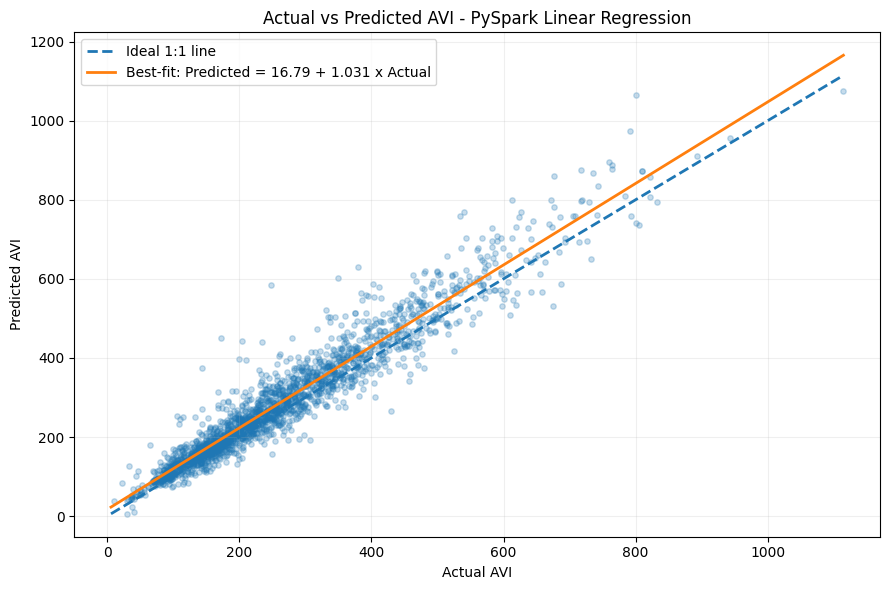

Pearson r: 0.9613
Evaluation R2: 0.8833
Best-fit slope: 1.0306
Best-fit intercept: 16.7864


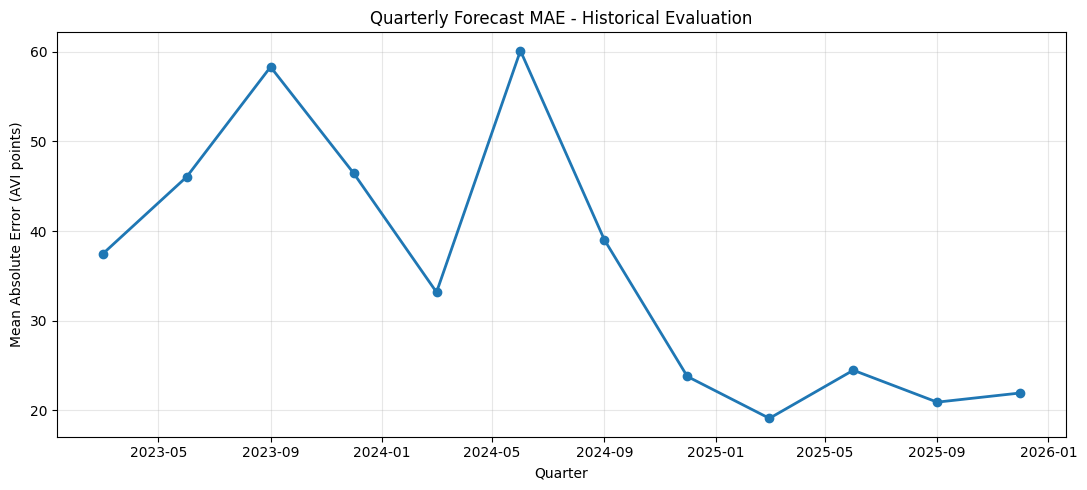

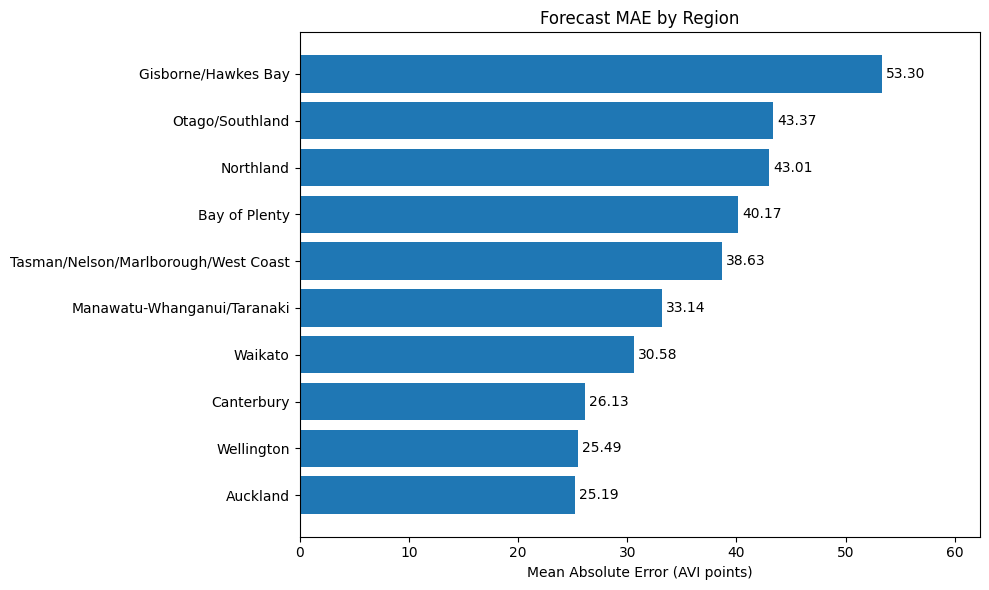

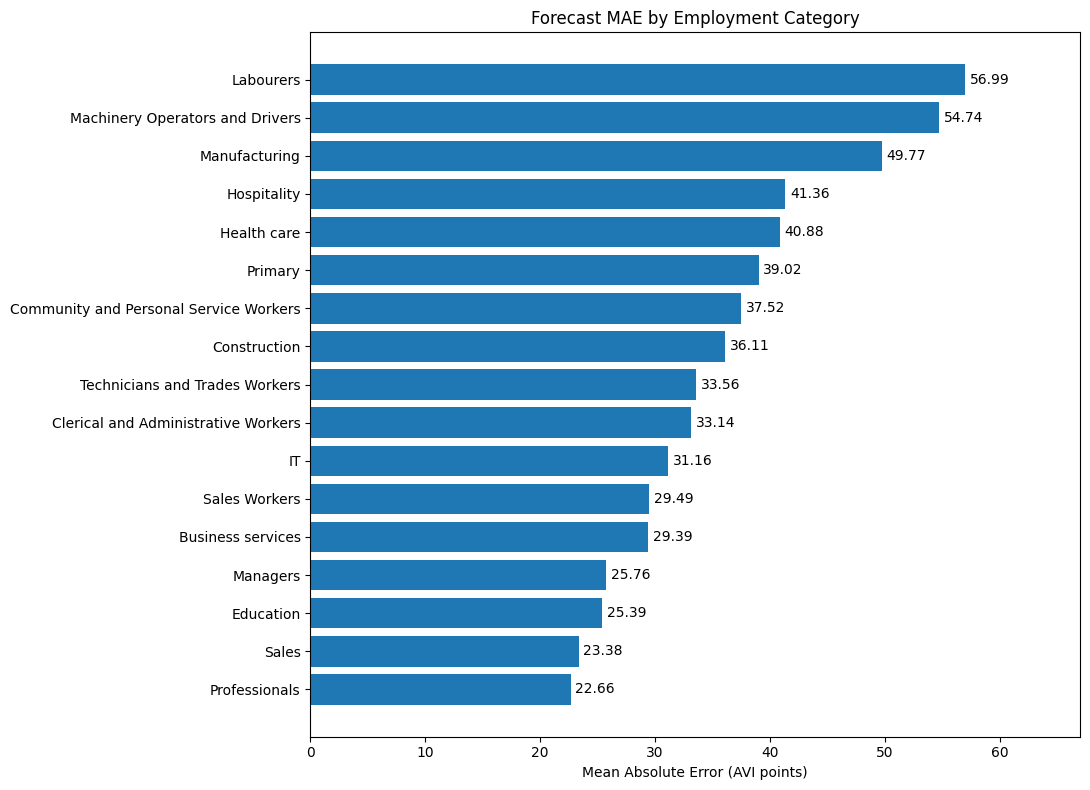

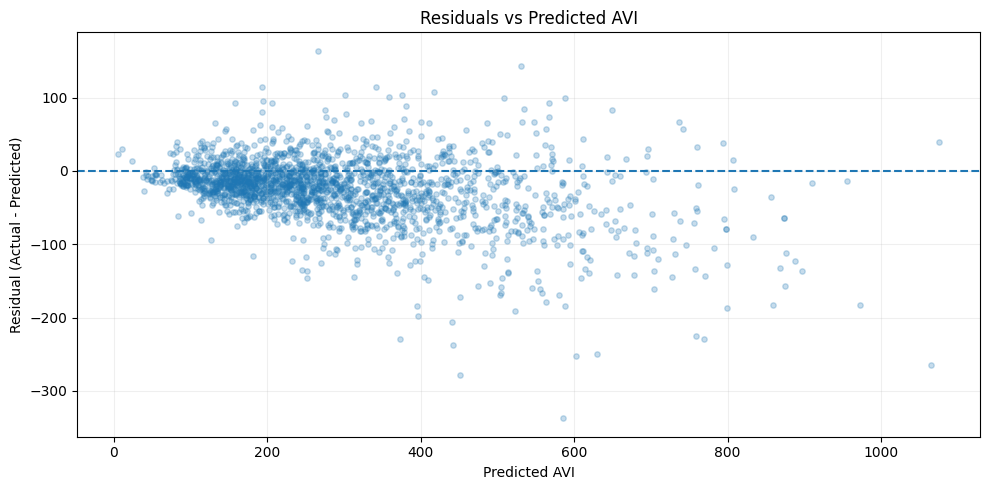

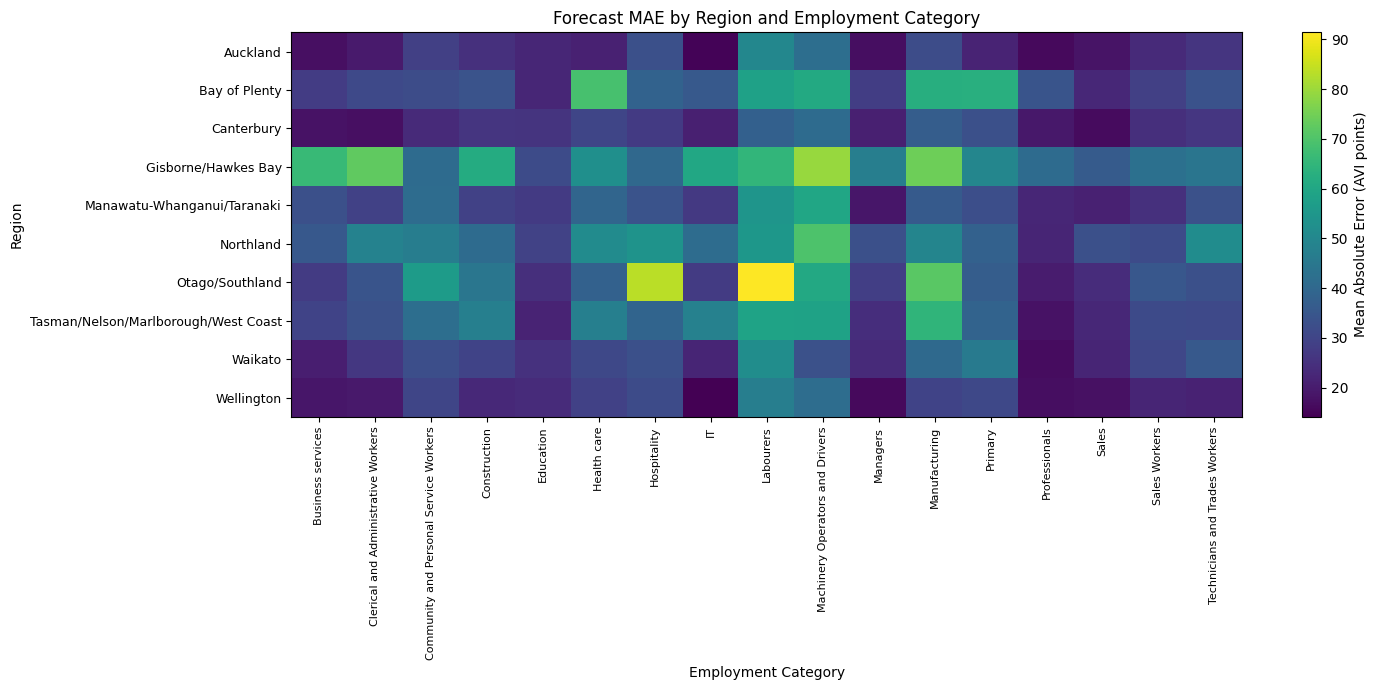


Figures saved in: /content/figures
STEP 8.2 COMPLETE


In [21]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pyspark.sql import functions as F
from sklearn.metrics import r2_score

print("=" * 65)
print("STEP 8.2 - VISUALISE THE RESULTS AND PATTERNS")
print("=" * 65)

# Create directory for generated figures
FIGURE_DIR = "/content/figures"
os.makedirs(FIGURE_DIR, exist_ok=True)

# Only transfer the final 2,040 evaluation rows to pandas for plotting.
# All modelling, aggregations and predictions are performed in PySpark.
plot_data = (
    final_predictions
    .select(
        "ACTUAL_DATE", "KEYA", "KEYBB",
        "AVI_SUM", "prediction", "Residual", "Absolute_Error"
    )
    .toPandas()
)

def save_figure(filename):
    plt.tight_layout()
    plt.savefig(
        os.path.join(FIGURE_DIR, filename),
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()

# ---------------------------------------------------------
# Figure 8.2.1 - Actual vs predicted AVI
# ---------------------------------------------------------
actual = plot_data["AVI_SUM"].to_numpy()
predicted = plot_data["prediction"].to_numpy()

slope, intercept = np.polyfit(actual, predicted, 1)
pearson_r = np.corrcoef(actual, predicted)[0, 1]
model_r2 = r2_score(actual, predicted)

line_min = min(actual.min(), predicted.min())
line_max = max(actual.max(), predicted.max())
line_x = np.linspace(line_min, line_max, 200)

plt.figure(figsize=(9, 6))
plt.scatter(actual, predicted, alpha=0.25, s=15)
plt.plot(
    line_x, line_x,
    linestyle="--",
    linewidth=2,
    label="Ideal 1:1 line"
)
plt.plot(
    line_x,
    intercept + slope * line_x,
    linewidth=2,
    label=f"Best-fit: Predicted = {intercept:.2f} + {slope:.3f} x Actual"
)
plt.xlabel("Actual AVI")
plt.ylabel("Predicted AVI")
plt.title("Actual vs Predicted AVI - PySpark Linear Regression")
plt.legend()
plt.grid(alpha=0.2)

save_figure("08_01_actual_vs_predicted.png")

print(f"Pearson r: {pearson_r:.4f}")
print(f"Evaluation R2: {model_r2:.4f}")
print(f"Best-fit slope: {slope:.4f}")
print(f"Best-fit intercept: {intercept:.4f}")

# ---------------------------------------------------------
# Figure 8.2.2 - Quarterly MAE
# ---------------------------------------------------------
quarter_plot = (
    quarterly_errors
    .select("ACTUAL_DATE", "MAE")
    .orderBy("ACTUAL_DATE")
    .toPandas()
)

plt.figure(figsize=(11, 5))
plt.plot(
    quarter_plot["ACTUAL_DATE"],
    quarter_plot["MAE"],
    marker="o",
    linewidth=2
)
plt.title("Quarterly Forecast MAE - Historical Evaluation")
plt.xlabel("Quarter")
plt.ylabel("Mean Absolute Error (AVI points)")
plt.grid(alpha=0.3)

save_figure("08_02_quarterly_mae.png")

# ---------------------------------------------------------
# Figure 8.2.3 - Regional MAE
# ---------------------------------------------------------
region_plot = (
    regional_errors
    .select("KEYA", "MAE")
    .orderBy(F.asc("MAE"))
    .toPandas()
)

plt.figure(figsize=(10, 6))
bars = plt.barh(region_plot["KEYA"], region_plot["MAE"])

for bar in bars:
    plt.text(
        bar.get_width() + 0.4,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.2f}",
        va="center"
    )

plt.xlim(0, region_plot["MAE"].max() + 9)
plt.title("Forecast MAE by Region")
plt.xlabel("Mean Absolute Error (AVI points)")

save_figure("08_03_regional_mae.png")

# ---------------------------------------------------------
# Figure 8.2.4 - Employment-category MAE
# ---------------------------------------------------------
category_plot = (
    category_errors
    .select("KEYBB", "MAE")
    .orderBy(F.asc("MAE"))
    .toPandas()
)

plt.figure(figsize=(11, 8))
bars = plt.barh(category_plot["KEYBB"], category_plot["MAE"])

for bar in bars:
    plt.text(
        bar.get_width() + 0.4,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.2f}",
        va="center"
    )

plt.xlim(0, category_plot["MAE"].max() + 10)
plt.title("Forecast MAE by Employment Category")
plt.xlabel("Mean Absolute Error (AVI points)")

save_figure("08_04_category_mae.png")

# ---------------------------------------------------------
# Figure 8.2.5 - Residuals vs predicted AVI
# Residual = Actual - Predicted
# ---------------------------------------------------------
plt.figure(figsize=(10, 5))
plt.scatter(
    plot_data["prediction"],
    plot_data["Residual"],
    alpha=0.25,
    s=15
)
plt.axhline(0, linestyle="--", linewidth=1.5)
plt.title("Residuals vs Predicted AVI")
plt.xlabel("Predicted AVI")
plt.ylabel("Residual (Actual - Predicted)")
plt.grid(alpha=0.2)

save_figure("08_05_residual_diagnostic.png")

# ---------------------------------------------------------
# Figure 8.2.6 - Region x category MAE heatmap
# Calculate subgroup error using PySpark
# ---------------------------------------------------------
heatmap_spark = (
    final_predictions
    .groupBy("KEYA", "KEYBB")
    .agg(
        F.avg("Absolute_Error").alias("MAE")
    )
)

heatmap_data = heatmap_spark.toPandas()

heatmap_table = heatmap_data.pivot(
    index="KEYA",
    columns="KEYBB",
    values="MAE"
).sort_index()

fig, ax = plt.subplots(figsize=(15, 7))
im = ax.imshow(
    heatmap_table.values,
    aspect="auto",
    cmap="viridis"
)

ax.set_xticks(range(len(heatmap_table.columns)))
ax.set_xticklabels(
    heatmap_table.columns,
    rotation=90,
    fontsize=8
)

ax.set_yticks(range(len(heatmap_table.index)))
ax.set_yticklabels(
    heatmap_table.index,
    fontsize=9
)

ax.set_title("Forecast MAE by Region and Employment Category")
ax.set_xlabel("Employment Category")
ax.set_ylabel("Region")

fig.colorbar(
    im,
    ax=ax,
    label="Mean Absolute Error (AVI points)"
)

save_figure("08_06_region_category_heatmap.png")

print("\nFigures saved in:", FIGURE_DIR)
print("STEP 8.2 COMPLETE")


### Step 8.3 — Interpret the Results

The PySpark model predicts how online job advertisement activity may change in different New Zealand regions and employment categories. Its average prediction error was approximately 36 AVI index points. This does not mean 36 jobs, because AVI measures changes in advertisement activity rather than the actual number of vacancies.

The model performed better than simply assuming that the next quarter would be the same as the previous one. However, its predictions were generally higher than the observed values, especially when advertisement activity was high.

Accuracy also differed between regions and types of work. For example, forecasts for Auckland were more reliable than those for Gisborne/Hawkes Bay, while predictions for Professionals were more accurate than those for Labourers.

For workforce planners, these forecasts are best used as an early indication of where labour demand may be changing. They can help identify regions or occupations that deserve attention, but should be checked against other labour-market information before important decisions are made.

### Step 8.4 — Assess and Evaluate the Results

The main technical objective was achieved. The PySpark Linear Regression model reduced the historical evaluation MAE from 39.995 for the previous-quarter baseline to 35.901, an improvement of 10.24%.

The workflow also covered all 170 selected region-category series and reproduced results close to the previous Python implementation. This indicates that the data preparation and forecasting logic can be transferred to PySpark without materially changing the predictions.

However, the model is less dependable in periods of large changes in advertisement activity. Errors also vary substantially across regions and employment categories, so a single overall accuracy figure does not represent every forecast equally well.

From a practical perspective, the workflow is useful for producing repeatable quarterly forecasts and identifying areas that need closer investigation. It does not provide sufficiently consistent accuracy to support automated workforce decisions.

The evaluation also has a limitation: the 2023–2025 data had already been examined in Iteration 3. Although the Iteration 4 model was selected using only development-period validation, the historical evaluation is not completely independent across the wider project.

Overall, the model meets the technical improvement target and provides useful monitoring information, but its forecasts should be interpreted with caution, particularly for high-AVI observations and high-error groups.

### Step 8.5A — Return to Step 4: Construct Volatility Features

Earlier analysis suggested that forecast errors tend to be larger when AVI levels fluctuate substantially. Volatility features were also explored in Iteration 3. In this iteration, I reimplemented that feature representation using PySpark to test whether it could improve development-period forecasting accuracy.

Two predictors were constructed using only the five previously observed quarterly AVI values: Lag_SD_5, which measures their standard deviation, and Lag_Range_5, which measures the difference between their maximum and minimum. Neither feature uses the current-quarter target AVI.

In [22]:

from pyspark.sql import functions as F

print("=" * 60)
print("STEP 8.5A - REVISIT STEP 4: VOLATILITY FEATURES")
print("=" * 60)

lag_columns = [f"AVI_SUM__{i}" for i in range(1, 6)]

# Mean of the five previous quarters
lag_mean_expr = sum(
    F.col(c) for c in lag_columns
) / F.lit(5.0)

# Population standard deviation of five lag values
lag_variance_expr = sum(
    (F.col(c) - lag_mean_expr) ** 2
    for c in lag_columns
) / F.lit(5.0)

# Maximum minus minimum across five historical quarters
lag_range_expr = (
    F.greatest(*[F.col(c) for c in lag_columns])
    - F.least(*[F.col(c) for c in lag_columns])
)

# Create new features on development data only
iteration_dev = (
    development
    .withColumn("Lag_SD_5", F.sqrt(lag_variance_expr))
    .withColumn("Lag_Range_5", lag_range_expr)
)

print("Development rows:", iteration_dev.count())

print("\nVolatility feature statistics:")
iteration_dev.select(
    "Lag_SD_5", "Lag_Range_5"
).summary().show()

print("\nExample constructed features:")
(
    iteration_dev
    .select(
        "ACTUAL_DATE",
        "KEYA",
        "KEYBB",
        "Lag_SD_5",
        "Lag_Range_5"
    )
    .orderBy("ACTUAL_DATE", "KEYA", "KEYBB")
    .show(8, truncate=False)
)

assert iteration_dev.count() == 7480

print("\nSTEP 8.5A COMPLETE")


STEP 8.5A - REVISIT STEP 4: VOLATILITY FEATURES
Development rows: 7480

Volatility feature statistics:
+-------+------------------+------------------+
|summary|          Lag_SD_5|       Lag_Range_5|
+-------+------------------+------------------+
|  count|              7480|              7480|
|   mean|29.436624648297997| 82.13598262032045|
| stddev|24.400029836063368| 69.69610506445049|
|    min|1.7565876010037158|4.8999999999999915|
|    25%|14.507708295937029| 40.20000000000002|
|    50%|21.527136363204466|60.099999999999994|
|    75%| 35.69613839058786| 99.24000000000001|
|    max|235.62076456882997|            639.13|
+-------+------------------+------------------+


Example constructed features:
+-----------+--------+--------------------------------------+------------------+------------------+
|ACTUAL_DATE|KEYA    |KEYBB                                 |Lag_SD_5          |Lag_Range_5       |
+-----------+--------+--------------------------------------+------------------+---------

### Step 8.5B — Return to Step 6: Rerun the Model

The original five-lag Linear Regression model was compared with a revised model containing the same five lags plus Lag_SD_5 and Lag_Range_5. Both were evaluated using the same four expanding-window validation folds from 2019 to 2022. The comparison was restricted to development-period data; the previously examined 2023–2025 historical evaluation observations were not used for this feature experiment.

In [23]:

from pyspark.sql import functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression
from pyspark.ml.evaluation import RegressionEvaluator

print("=" * 60)
print("STEP 8.5B - RERUN DEVELOPMENT VALIDATION")
print("=" * 60)

baseline_features = [f"AVI_SUM__{i}" for i in range(1, 6)]

volatility_features = baseline_features + [
    "Lag_SD_5",
    "Lag_Range_5"
]

iteration_feature_sets = {
    "Original five-lag model": baseline_features,
    "Five lags + volatility": volatility_features
}

iteration_folds = [
    (2018, 2019),
    (2019, 2020),
    (2020, 2021),
    (2021, 2022)
]

mae_evaluator = RegressionEvaluator(
    labelCol="AVI_SUM",
    predictionCol="prediction",
    metricName="mae"
)

iteration_results = []

for model_name, feature_columns in iteration_feature_sets.items():

    print(f"\n{model_name}")
    print("-" * 45)

    for train_end, validation_year in iteration_folds:

        train = iteration_dev.filter(
            F.col("Year") <= train_end
        )

        valid = iteration_dev.filter(
            F.col("Year") == validation_year
        )

        iteration_pipeline = Pipeline(stages=[
            VectorAssembler(
                inputCols=feature_columns,
                outputCol="features",
                handleInvalid="error"
            ),
            LinearRegression(
                featuresCol="features",
                labelCol="AVI_SUM",
                predictionCol="prediction",
                regParam=0.0,
                elasticNetParam=0.0,
                fitIntercept=True,
                maxIter=100
            )
        ])

        fitted = iteration_pipeline.fit(train)
        predictions = fitted.transform(valid)

        mae = mae_evaluator.evaluate(predictions)

        iteration_results.append(
            (model_name, validation_year, float(mae))
        )

        print(f"Validation {validation_year}: MAE = {mae:.3f}")

iteration_results_df = spark.createDataFrame(
    iteration_results,
    ["Iteration", "Validation_Year", "MAE"]
)

iteration_summary = (
    iteration_results_df
    .groupBy("Iteration")
    .agg(
        F.avg("MAE").alias("Mean_MAE"),
        F.stddev("MAE").alias("SD_MAE")
    )
    .orderBy("Mean_MAE")
)

print("\nFINAL ITERATION COMPARISON:")
iteration_summary.show(truncate=False)

print("\nSTEP 8.5B COMPLETE")


STEP 8.5B - RERUN DEVELOPMENT VALIDATION

Original five-lag model
---------------------------------------------
Validation 2019: MAE = 25.824
Validation 2020: MAE = 61.437
Validation 2021: MAE = 76.441
Validation 2022: MAE = 50.143

Five lags + volatility
---------------------------------------------
Validation 2019: MAE = 25.674
Validation 2020: MAE = 59.209
Validation 2021: MAE = 63.451
Validation 2022: MAE = 44.024

FINAL ITERATION COMPARISON:
+-----------------------+------------------+------------------+
|Iteration              |Mean_MAE          |SD_MAE            |
+-----------------------+------------------+------------------+
|Five lags + volatility |48.089367358651735|17.11325452896382 |
|Original five-lag model|53.46116289553804 |21.342615739826304|
+-----------------------+------------------+------------------+


STEP 8.5B COMPLETE


### Step 8.5C — Compare and Interpret the Iteration

I revisited Step 4 to construct two volatility features from the previous five quarterly AVI observations, then returned to Step 6 to rerun the same expanding-window validation. This was a PySpark reimplementation of a feature idea previously explored in Iteration 3.

The revised model reduced mean development validation MAE from 53.461 to 48.089, an improvement of approximately 10.0%. All four validation years improved, with the largest reduction occurring in 2021, when MAE fell from 76.441 to 63.451. The standard deviation of annual validation MAE also decreased from 21.343 to 17.113.

These findings suggest that recent fluctuations contain useful forecasting information beyond the five lag values alone. However, the volatility features were already considered in the previous iteration, and the 2023–2025 evaluation period has been examined before. I therefore treat this result as development-stage evidence rather than a new independent test of forecasting performance.

The formal Iteration 4 historical evaluation remains based on the five-lag Linear Regression model, with MAE 35.901. The volatility-enhanced specification is recorded as a candidate for further evaluation using genuinely new quarterly observations.

STEP 8.5 - VISUALISE ITERATION COMPARISON


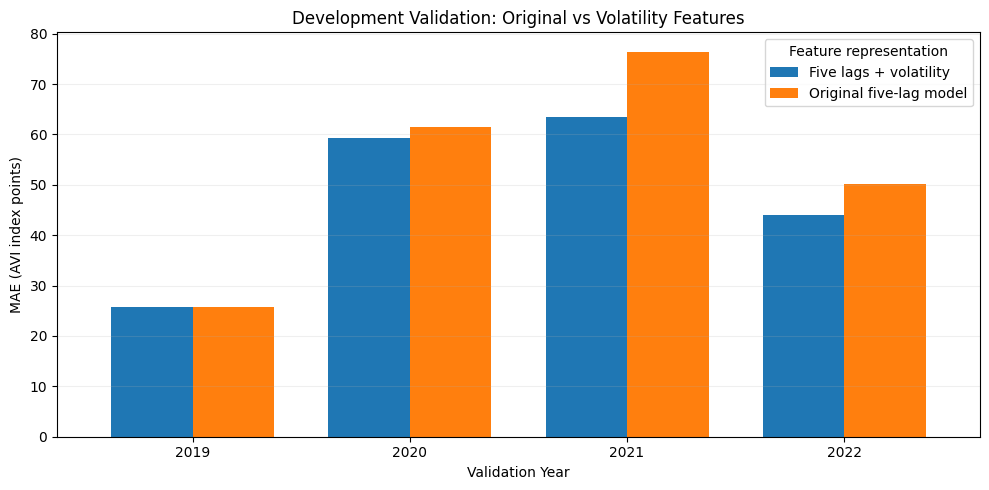

STEP 8.5 COMPLETE


In [24]:

import matplotlib.pyplot as plt
import os

print("STEP 8.5 - VISUALISE ITERATION COMPARISON")

iteration_plot = (
    iteration_results_df
    .orderBy("Validation_Year", "Iteration")
    .toPandas()
)

pivot = iteration_plot.pivot(
    index="Validation_Year",
    columns="Iteration",
    values="MAE"
).sort_index()

ax = pivot.plot(
    kind="bar",
    figsize=(10, 5),
    width=0.75
)

ax.set_title(
    "Development Validation: Original vs Volatility Features"
)
ax.set_xlabel("Validation Year")
ax.set_ylabel("MAE (AVI index points)")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Feature representation")
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()

os.makedirs("/content/figures", exist_ok=True)

plt.savefig(
    "/content/figures/08_07_iteration_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("STEP 8.5 COMPLETE")
